# 06 – Kiểm định chéo, tinh chỉnh siêu tham số, learning curve (P4, rubric III 25%)

**Mục tiêu theo rubric (mức xuất sắc):** baseline khoa học; ≥ 3 thuật toán nâng cao; Cross-Validation bài bản; tinh chỉnh bằng GridSearch; learning curve chứng minh không over/underfitting.

**Thiết kế:**
1. Tinh chỉnh trên **B (Shopee train, 22 sản phẩm)** bằng **GroupKFold(5) theo sản phẩm**. Một sản phẩm không bao giờ nằm ở cả fold train lẫn fold validation.
   - Vì sao không tinh chỉnh trên A+B: ViSD4SA không có cột sản phẩm nên không chia nhóm được.
   - Vì sao không tinh chỉnh trên tập vàng: tập vàng chỉ để **đánh giá cuối cùng**. Chọn tham số trên nó là rò rỉ.
2. Lấy tham số tốt nhất, **huấn luyện lại trên A+B và A+B+Aug**, rồi đánh giá trên ViSD4SA test (trong miền) và tập vàng (ngoài miền).
3. Lưu mô hình vào `models/` cho notebook đánh giá (09), ABSA (10) và app.

In [1]:
import sys, os, time, joblib
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, KFold, StratifiedKFold, GridSearchCV, cross_val_score, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score
from src.data import load_sets, load_gold
from src.features import features_array

FIG, REP, MOD = "../figures", "../report", "../models"
for d in (FIG, REP, MOD): os.makedirs(d, exist_ok=True)
SEED = 42

S = load_sets()
B = S["B"]
gold, GOLD_TEMP = load_gold()
print("Tập vàng:", "TẠM nhãn sao (chưa đủ nhãn tay)" if GOLD_TEMP else "nhãn tay", len(gold), "câu")
X_B, y_B, g_B = B[["text_prep", "text_raw"]], B.label, B.group
cv = GroupKFold(n_splits=5)
print("Số sản phẩm mỗi fold validation:", [g_B.iloc[va].nunique() for _, va in cv.split(X_B, y_B, g_B)])

Tập vàng: nhãn tay 300 câu
Số sản phẩm mỗi fold validation: [1, 6, 5, 5, 5]


## 1. Baseline: BoW + Naive Bayes, đánh giá bằng cùng GroupKFold

In [2]:
baseline = Pipeline([("vec", ColumnTransformer([("bow", CountVectorizer(ngram_range=(1, 2), min_df=2), "text_prep")])),
                     ("clf", MultinomialNB())])
sc = cross_val_score(baseline, X_B, y_B, groups=g_B, cv=cv, scoring="f1_macro")
print(f"Baseline BoW+NB: F1-macro CV = {sc.mean():.3f} ± {sc.std():.3f}")
cv_rows = [{"model": "BoW+NB (baseline)", "best_params": "mặc định", "cv_f1_mean": sc.mean(), "cv_f1_std": sc.std()}]

Baseline BoW+NB: F1-macro CV = 0.601 ± 0.017


## 2. GridSearchCV: TF-IDF + Logistic Regression và TF-IDF + LinearSVC

- `ngram_range`: có lấy bigram ("không tốt") hay không.
- `min_df`: bỏ từ hiếm (nhiễu, lỗi gõ).
- `C`: nghịch đảo độ mạnh điều chuẩn. C nhỏ thì mô hình đơn giản hơn, ít overfit hơn.

In [3]:
def text_pipe(clf):
    return Pipeline([("vec", ColumnTransformer([("tfidf", TfidfVectorizer(sublinear_tf=True), "text_prep")])),
                     ("clf", clf)])

grids = {
    "TF-IDF+LR": (text_pipe(LogisticRegression(max_iter=3000, class_weight="balanced")),
                  {"vec__tfidf__ngram_range": [(1, 1), (1, 2)], "vec__tfidf__min_df": [1, 2, 3],
                   "clf__C": [0.3, 1, 3, 10]}),
    "TF-IDF+LinearSVC": (text_pipe(LinearSVC(class_weight="balanced")),
                         {"vec__tfidf__ngram_range": [(1, 1), (1, 2)], "vec__tfidf__min_df": [1, 2, 3],
                          "clf__C": [0.03, 0.1, 0.3, 1]}),
}
searches = {}
for name, (pipe, grid) in grids.items():
    t = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
    gs.fit(X_B, y_B, groups=g_B)
    searches[name] = gs
    i = gs.best_index_
    print(f"{name}: {len(gs.cv_results_['params'])} cấu hình × 5 fold, {time.time()-t:.0f}s")
    print(f"   tốt nhất {gs.best_params_}  F1 = {gs.best_score_:.3f} ± {gs.cv_results_['std_test_score'][i]:.3f}"
          f"  (train F1 = {gs.cv_results_['mean_train_score'][i]:.3f})")
    cv_rows.append({"model": name, "best_params": str({k.split('__')[-1]: v for k, v in gs.best_params_.items()}),
                    "cv_f1_mean": gs.best_score_, "cv_f1_std": gs.cv_results_["std_test_score"][i]})

TF-IDF+LR: 24 cấu hình × 5 fold, 27s
   tốt nhất {'clf__C': 10, 'vec__tfidf__min_df': 2, 'vec__tfidf__ngram_range': (1, 2)}  F1 = 0.665 ± 0.046  (train F1 = 1.000)


TF-IDF+LinearSVC: 24 cấu hình × 5 fold, 11s
   tốt nhất {'clf__C': 1, 'vec__tfidf__min_df': 2, 'vec__tfidf__ngram_range': (1, 2)}  F1 = 0.658 ± 0.061  (train F1 = 1.000)


In [4]:
# Toàn bộ kết quả lưới của LR: xem tham số nào ảnh hưởng nhiều nhất
r = pd.DataFrame(searches["TF-IDF+LR"].cv_results_)
r = r[["param_vec__tfidf__ngram_range", "param_vec__tfidf__min_df", "param_clf__C", "mean_train_score", "mean_test_score", "std_test_score"]]
r.columns = ["ngram", "min_df", "C", "F1_train", "F1_val", "std_val"]
r.sort_values("F1_val", ascending=False).round(3).head(10)

,ngram,min_df,C,F1_train,F1_val,std_val
21,"(1, 2)",2,10.0,1.000,0.665,0.046
15,"(1, 2)",2,3.0,0.991,0.656,0.044
17,"(1, 2)",3,3.0,0.987,0.656,0.033
23,"(1, 2)",3,10.0,1.000,0.652,0.033
19,"(1, 2)",1,10.0,1.000,0.648,0.048
13,"(1, 2)",1,3.0,0.999,0.646,0.052
11,"(1, 2)",3,1.0,0.957,0.641,0.042
9,"(1, 2)",2,1.0,0.978,0.639,0.044
22,"(1, 1)",3,10.0,0.995,0.634,0.117
7,"(1, 2)",1,1.0,0.990,0.634,0.047


**Đọc bảng:** `F1_train` gần 1 trong khi `F1_val` khoảng 0,6 nghĩa là mô hình **học thuộc** tập train (overfitting). C nhỏ thu hẹp khoảng cách này. Cần ghi vào báo cáo: chênh train–val bao nhiêu ở cấu hình được chọn.

## 3. Feature engineering: TF-IDF + 6 đặc trưng mới

Ghép ma trận TF-IDF với 6 đặc trưng ở `src/features.py` (đã chuẩn hóa thang đo bằng `StandardScaler`). So với TF-IDF+LR thuần trên **cùng các fold**. Đặc trưng nào giúp thì rubric tính là "feature engineering giúp mô hình chính xác hơn". Không giúp cũng phải báo.

In [5]:
best_lr = searches["TF-IDF+LR"].best_params_
feat_pipe = Pipeline([
    ("vec", ColumnTransformer([
        ("tfidf", TfidfVectorizer(sublinear_tf=True, ngram_range=best_lr["vec__tfidf__ngram_range"],
                                  min_df=best_lr["vec__tfidf__min_df"]), "text_prep"),
        ("feat", Pipeline([("f", FunctionTransformer(features_array)), ("sc", StandardScaler())]), "text_raw"),
    ])),
    ("clf", LogisticRegression(max_iter=3000, class_weight="balanced")),
])
gs_feat = GridSearchCV(feat_pipe, {"clf__C": [0.3, 1, 3, 10]},
                       cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
gs_feat.fit(X_B, y_B, groups=g_B)
searches["TF-IDF+đặc trưng+LR"] = gs_feat
i = gs_feat.best_index_
print(f"TF-IDF + đặc trưng + LR: F1 = {gs_feat.best_score_:.3f} ± {gs_feat.cv_results_['std_test_score'][i]:.3f}, C = {gs_feat.best_params_['clf__C']}")
print(f"TF-IDF + LR thuần      : F1 = {searches['TF-IDF+LR'].best_score_:.3f}")
cv_rows.append({"model": "TF-IDF+đặc trưng+LR", "best_params": f"C={gs_feat.best_params_['clf__C']}",
                "cv_f1_mean": gs_feat.best_score_, "cv_f1_std": gs_feat.cv_results_["std_test_score"][i]})

# so sánh từng fold (cặp) để biết chênh lệch có nhất quán không
f_plain = [searches["TF-IDF+LR"].cv_results_[f"split{k}_test_score"][searches["TF-IDF+LR"].best_index_] for k in range(5)]
f_feat = [gs_feat.cv_results_[f"split{k}_test_score"][i] for k in range(5)]
pd.DataFrame({"fold": range(1, 6), "TF-IDF+LR": f_plain, "+ đặc trưng": f_feat}).round(3).assign(
    chenh=lambda d: (d["+ đặc trưng"] - d["TF-IDF+LR"]).round(3))

TF-IDF + đặc trưng + LR: F1 = 0.631 ± 0.045, C = 3
TF-IDF + LR thuần      : F1 = 0.665


,fold,TF-IDF+LR,+ đặc trưng,chenh
0,1,0.597,0.547,-0.050
1,2,0.632,0.653,0.021
2,3,0.713,0.663,-0.050
3,4,0.664,0.620,-0.044
4,5,0.717,0.671,-0.046


## 4. Vì sao phải dùng GroupKFold? So với KFold xáo ngẫu nhiên

In [6]:
best_pipe = searches["TF-IDF+LR"].best_estimator_
leak = cross_val_score(best_pipe, X_B, y_B, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1_macro")
grp = cross_val_score(best_pipe, X_B, y_B, groups=g_B, cv=cv, scoring="f1_macro")
print(f"StratifiedKFold xáo ngẫu nhiên: {leak.mean():.3f} ± {leak.std():.3f}")
print(f"GroupKFold theo sản phẩm       : {grp.mean():.3f} ± {grp.std():.3f}")
print("Chênh lệch = mức 'lạc quan giả' khi cùng sản phẩm nằm ở cả train và validation.")

StratifiedKFold xáo ngẫu nhiên: 0.673 ± 0.041
GroupKFold theo sản phẩm       : 0.665 ± 0.046
Chênh lệch = mức 'lạc quan giả' khi cùng sản phẩm nằm ở cả train và validation.


## 5. Learning curve

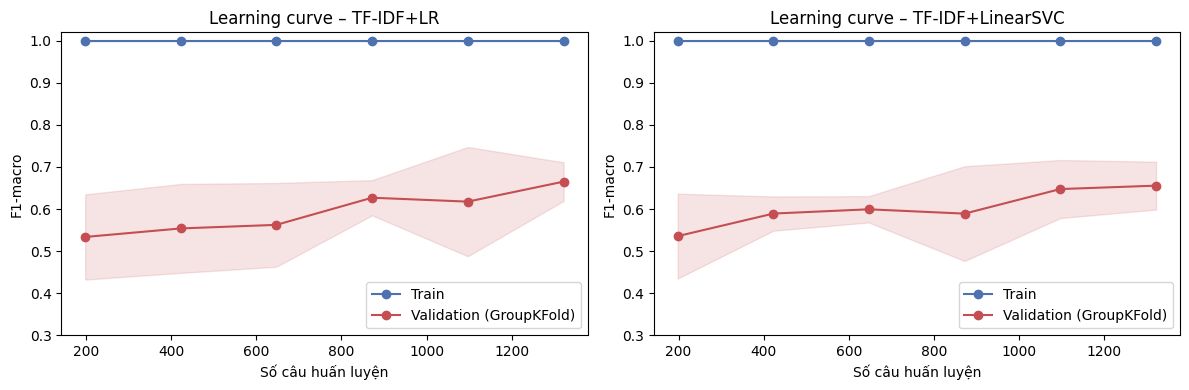

,model,n_train,f1_train,f1_val
0,TF-IDF+LR,198,1.0,0.534
1,TF-IDF+LR,423,1.0,0.554
2,TF-IDF+LR,647,1.0,0.562
3,TF-IDF+LR,872,1.0,0.627
4,TF-IDF+LR,1097,1.0,0.618
5,TF-IDF+LR,1322,1.0,0.665
6,TF-IDF+LinearSVC,198,1.0,0.536
7,TF-IDF+LinearSVC,423,1.0,0.589
8,TF-IDF+LinearSVC,647,1.0,0.599
9,TF-IDF+LinearSVC,872,1.0,0.589


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lc_rows = []
for ax, name in zip(axes, ["TF-IDF+LR", "TF-IDF+LinearSVC"]):
    sizes, tr_sc, va_sc = learning_curve(searches[name].best_estimator_, X_B, y_B, groups=g_B, cv=cv,
                                         scoring="f1_macro", train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1)
    for lab, s, c in [("Train", tr_sc, "#4C72B0"), ("Validation (GroupKFold)", va_sc, "#C44E52")]:
        ax.plot(sizes, s.mean(1), "o-", color=c, label=lab)
        ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.15, color=c)
    ax.set(title=f"Learning curve – {name}", xlabel="Số câu huấn luyện", ylabel="F1-macro", ylim=(0.3, 1.02))
    ax.legend(loc="lower right")
    lc_rows += [{"model": name, "n_train": n, "f1_train": a, "f1_val": b}
                for n, a, b in zip(sizes, tr_sc.mean(1), va_sc.mean(1))]
plt.tight_layout(); plt.savefig(f"{FIG}/learning_curve_classic.png", bbox_inches="tight"); plt.show()
pd.DataFrame(lc_rows).round(3).to_csv(f"{REP}/learning_curve_classic.csv", index=False)
pd.DataFrame(lc_rows).round(3)

**Nhận xét.** Learning curve có F1 train 1,000 nhưng validation thấp hơn nhiều. Với LR, validation tăng từ 0,534 lên 0,665 khi mẫu train tăng từ 198 lên 1.322; SVC từ 0,536 lên 0,656. Khoảng cách tổng quát hóa còn lớn. Thêm dữ liệu đa dạng là hướng cần thử, không bảo đảm tiếp tục tăng điểm. Điều chuẩn và CV theo sản phẩm giúp giảm rủi ro đánh giá lạc quan, không chứng minh đã hết quá khớp.

## 6. Huấn luyện lại trên A+B, A+B+Aug và đánh giá

Giữ nguyên tham số tốt nhất từ CV. Báo hai con số: trong miền (ViSD4SA test) và ngoài miền (tập vàng).

In [8]:
from sklearn.base import clone
train_sets = {"B": S["B"], "A+B": pd.concat([S["A"], S["B"]], ignore_index=True),
              "A+B+Aug": pd.concat([S["A"], S["B"], S["Aug"]], ignore_index=True)}
cands = {"BoW+NB (baseline)": baseline, **{k: v.best_estimator_ for k, v in searches.items()}}
A_test = S["A_test"]
rows, fitted = [], {}
for cfg, d in train_sets.items():
    for name, est in cands.items():
        m = clone(est).fit(d[["text_prep", "text_raw"]], d.label)
        fitted[(cfg, name)] = m
        rows.append({"train": cfg, "model": name,
                     "F1_ViSD_test": f1_score(A_test.label, m.predict(A_test[["text_prep", "text_raw"]]), average="macro"),
                     "F1_gold": f1_score(gold.label, m.predict(gold[["text_prep", "text_raw"]]), average="macro")})
res = pd.DataFrame(rows)
res.to_csv(f"{REP}/tuned_results.csv", index=False)
print("Ngoài miền:", "TẠM nhãn sao" if GOLD_TEMP else "tập vàng nhãn tay")
res.pivot(index="model", columns="train", values="F1_gold").round(3)

Ngoài miền: tập vàng nhãn tay


train,A+B,A+B+Aug,B
model,,,
BoW+NB (baseline),0.583,0.558,0.607
TF-IDF+LR,0.605,0.603,0.608
TF-IDF+LinearSVC,0.601,0.600,0.605
TF-IDF+đặc trưng+LR,0.646,0.646,0.590


In [9]:
res.pivot(index="model", columns="train", values="F1_ViSD_test").round(3)

train,A+B,A+B+Aug,B
model,,,
BoW+NB (baseline),0.585,0.578,0.465
TF-IDF+LR,0.724,0.723,0.510
TF-IDF+LinearSVC,0.699,0.700,0.519
TF-IDF+đặc trưng+LR,0.719,0.727,0.524


In [10]:
pd.DataFrame(cv_rows).round(3).to_csv(f"{REP}/cv_results.csv", index=False)
pd.DataFrame(cv_rows).round(3)

,model,best_params,cv_f1_mean,cv_f1_std
0,BoW+NB (baseline),mặc định,0.601,0.017
1,TF-IDF+LR,"{'C': 10, 'min_df': 2, 'ngram_range': (1, 2)}",0.665,0.046
2,TF-IDF+LinearSVC,"{'C': 1, 'min_df': 2, 'ngram_range': (1, 2)}",0.658,0.061
3,TF-IDF+đặc trưng+LR,C=3,0.631,0.045


## 7. Lưu mô hình

Lưu các mô hình huấn luyện trên **A+B**. Đây là cấu hình dùng cho đánh giá chuyên sâu, ABSA và app. Nếu bảng ở mục 6 cho thấy A+B+Aug tốt hơn rõ trên tập vàng thì đổi `CFG`.

In [11]:
CFG = "A+B"
for name, fn in [("TF-IDF+LR", "tfidf_lr"), ("TF-IDF+LinearSVC", "tfidf_svc"),
                 ("TF-IDF+đặc trưng+LR", "tfidf_feat_lr"), ("BoW+NB (baseline)", "bow_nb")]:
    joblib.dump(fitted[(CFG, name)], f"{MOD}/{fn}_{CFG.replace('+', '')}.joblib")
# bản A+B+Aug của LR cho thí nghiệm không dấu
joblib.dump(fitted[("A+B+Aug", "TF-IDF+LR")], f"{MOD}/tfidf_lr_ABAug.joblib")
print(sorted(os.listdir(MOD)))

['aug_retrain', 'bow_nb_AB.joblib', 'relabel_retrain', 'shopee_retrain', 'tfidf_feat_lr_AB.joblib', 'tfidf_lr_AB.joblib', 'tfidf_lr_ABAug.joblib', 'tfidf_svc_AB.joblib']
